In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import nanonets

plt.style.use(["science","bright","grid"])

In [58]:
topology    = {"Nx": 1, "Ny": 1, "electrode_type" : ['constant','constant']}
sim         = nanonets.Simulation(topology, 0.0)
volt_charg  = sim.electrostatic.get_charging_energies()[0]*2

In [41]:
df = pd.read_csv("../../data/raw/time_independent/set/set_v_gate0.000_self_cap0.00.csv")
p = pd.read_parquet("../../data/raw/time_independent/set/mean_state_set_v_gate0.000_self_cap0.00.parquet").iloc[:,2].values*1e3
i = pd.read_parquet("../../data/raw/time_independent/set/net_currents_set_v_gate0.000_self_cap0.00.parquet").values*1e-9
x = df['E0'].values*1e3
y = df['Observable'].values*1e-9
y_e = df['Error'].values*1e-9

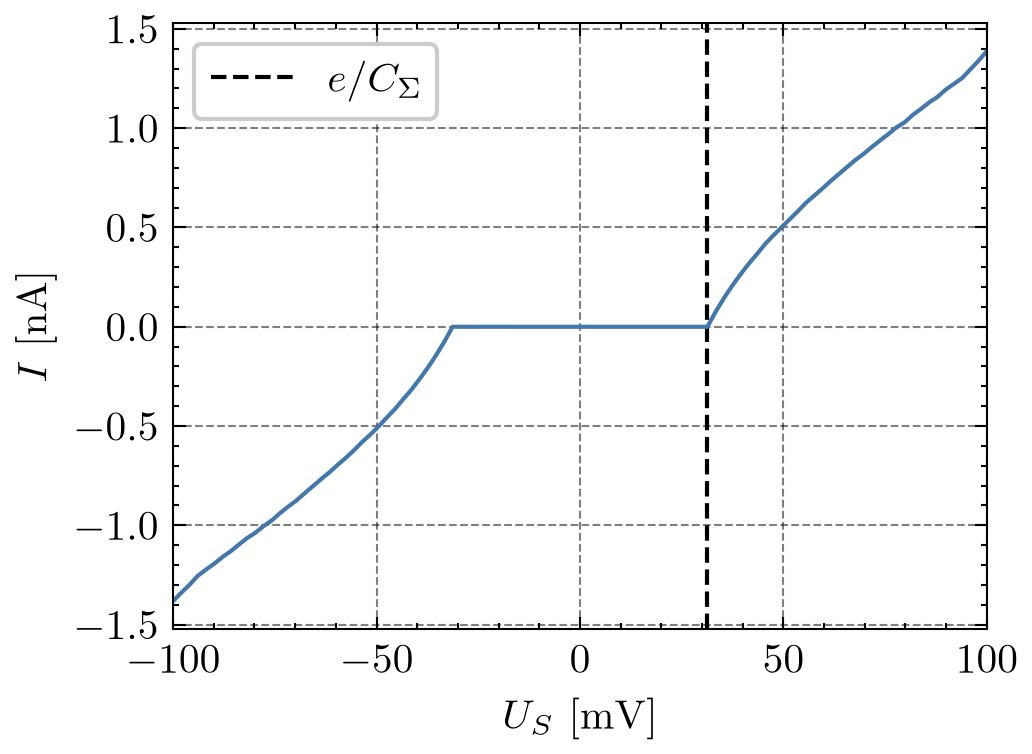

In [74]:
fig, ax = plt.subplots(dpi=300)
_       = ax.errorbar(x, y, y_e)
_       = ax.axvline(volt_charg, label='$e / C_\\Sigma$', color='black', ls='--')
_       = ax.set_xlabel("$U_S~[\\mathrm{mV}]$")
_       = ax.set_ylabel("$I~[\\mathrm{nA}]$")
_       = ax.legend()
_       = ax.set_xlim(-100,100)

fig.savefig("plots/set/set_iv_curve_zero_gate.svg", transparent=True, bbox_inches='tight')

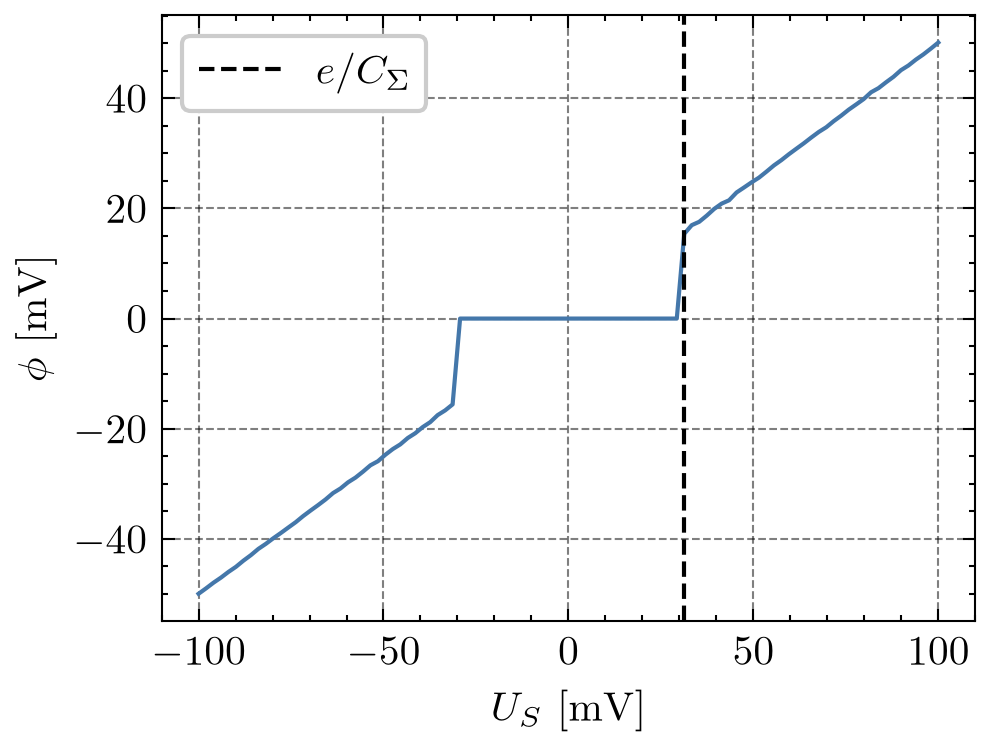

In [77]:
fig, ax = plt.subplots(dpi=300)
_       = ax.plot(x, p)
_       = ax.set_xlabel("$U_S~[\\mathrm{mV}]$")
_       = ax.set_ylabel("$\\phi~[\\mathrm{mV}]$")
_       = ax.axvline(volt_charg, label='$e / C_\\Sigma$', color='black', ls='--')
_       = ax.legend()

fig.savefig("plots/set/set_pot_curve_zero_gate.svg", transparent=True, bbox_inches='tight')